# Intro to Active Learning with BNN
- credits to Ivan Nazarov (Ivan.Nazarov@skoltech.ru)
- Also take a look at the recent paper by Ivan on Dropout for $\mathbb{C}$-valued NN, wich is accepted to the ICML 2020: https://proceedings.icml.cc/paper/2020/hash/7c05147f3029c97ce26c0cb0b2469fca

In this tutorial we will uncertainty estimation can be
used in active learning or expert-in-the-loop pipelines.

The plan of the tutorial
1. [Imports and definitions](#Imports-and-definitions)
2. [Bayesian Active Learning with images](#Bayesian-Active-Learning-with-images)
   1. [The model](#The-model)
   2. [the Acquisition Function](#the-Acquisition-Function)
   3. [Data and the Oracle](#Data-and-the-Oracle)
   4. [the Active Learning loop](#the-Active-Learning-loop)
   5. [The baseline](#The-baseline)
3. [Bayesian Active Learning by Disagreement](#Bayesian-Active-Learning-by-Disagreement)
   1. [Points of improvement: batch-vs-single](#Points-of-improvement:-batch-vs-single)
   2. [Points of improvement: bias](#Points-of-improvement:-bias)


**(note)**
* to view documentation on something  type in `something?` (with one question mark)
* to view code of something type in `something??` (with two question marks).

<br>

## Imports and definitions

In this section we import necessary modules and functions and
define the computational device.

First, we install some boilerplate service code for this tutorial.

In [1]:
!pip install -q --upgrade git+https://github.com/mlss-skoltech/tutorials.git#subdirectory=bayesian_deep_learning

  Preparing metadata (setup.py) ... done


Next, numpy for computing, matplotlib for plotting and tqdm for progress bars.

In [2]:
import tqdm
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plt

For deep learning stuff will be using [pytorch](https://pytorch.org/).

If you are unfamiliar with it, it is basically like `numpy` with autograd,
native GPU support, and tools for building training and serializing models.
<!-- (and with `axis` argument replaced with `dim` :) -->

There are good introductory tutorials on `pytorch`, like this
[one](https://pytorch.org/tutorials/beginner/deep_learning_60min_blitz.html).

In [4]:
import torch
import torch.nn.functional as F

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [5]:
device

device(type='cuda', index=0)

Next we import the boilerplate code.

* a procedure that implements a minibatch SGD **fit** loop
* a function, that **evaluates** the model on the provided dataset

In [6]:
from mlss2019bdl import fit, predict

The algorithm to sample a random function is:
* for $b = 1... B$ do:

  1. draw an independent realization $f_b\colon \mathcal{X} \to \mathcal{Y}$
  with from the process $\{f_\omega\}_{\omega \sim q(\omega)}$
  2. get $\hat{y}_{bi} = f_b(\tilde{x}_i)$ for $i=1 .. m$


In [7]:
from mlss2019bdl.bdl import freeze, unfreeze

def sample_function(model, dataset, n_draws=1, verbose=False):
    """Draw a realization of a random function."""
    outputs = []
    for _ in tqdm.tqdm(range(n_draws), disable=not verbose):
        freeze(model)
        outputs.append(predict(model, dataset))
    unfreeze(model)
    return torch.stack(outputs, dim=0)

Sample the class probabilities $p(y_x = k \mid x, \omega, m)$
with $\omega \sim q(\omega)$ by a model that **outputs raw class
logit scores**.

In [8]:
def sample_proba(model, dataset, n_draws=1):
    logits = sample_function(model, dataset, n_draws=n_draws)
    return F.softmax(logits, dim=-1)

Get the predictive posterior class probabilities
$:
p(y_x = k \mid x, m)
     = \mathbb{E}_{\omega \sim q(\omega)}
         p(y_x = k \mid x, \omega, m)
    \approx \frac1{\lvert \mathcal{W} \rvert}
        \sum_{\omega \in \mathcal{W}}
            p(y_x = k \mid x, \omega, m)
    \,,
$
with $\mathcal{W}$ -- iid draws from $q(\omega)$.

In [9]:
def predict_proba(model, dataset, n_draws=1):
    proba = sample_proba(model, dataset, n_draws=n_draws)
    return proba.mean(dim=0)

Get the maximum a posteriori class label **(MAP)**: $
\hat{y}_x
    = \arg \max_k \mathbb{E}_{\omega \sim q(\omega)}
        p(y_x = k \mid x, \omega, m)
$

In [10]:
def predict_label(model, dataset, n_draws=1):
    proba = predict_proba(model, dataset, n_draws=n_draws)

    return proba.argmax(dim=-1)

We will need some functionality from scikit

In [11]:
from sklearn.metrics import confusion_matrix

def evaluate(model, dataset, n_draws=1):
    assert isinstance(dataset, TensorDataset)
    predicted = predict_label(model, dataset, n_draws=n_draws)
    target = dataset.tensors[1].cpu().numpy()
    return confusion_matrix(target, predicted.cpu().numpy())

A function to plot images in a small dataset.

In [12]:
from mlss2019bdl.flex import plot
from torch.utils.data import TensorDataset
from IPython.display import clear_output

def display(images, n_col=None, title=None, figsize=None, refresh=False):
    if isinstance(images, TensorDataset):
        images, targets = images.tensors

    if refresh:
        clear_output(True)

    fig, ax = plt.subplots(1, 1, figsize=figsize)
    plot(ax, images, n_col=n_col, cmap=plt.cm.bone)
    if title is not None:
        ax.set_title(title)

    plt.show()
    plt.close()

<br>

## Bayesian Active Learning with images

* Data labelling is costly and time consuming
* unlabeled instances are essentially free

**Goal** Achieve high performance with fewer labels by
identifying the best instances to learn from

Essential blocks of active learning:

* a **model** $m$ capable of quantifying uncertainty (preferably a Bayesian model)
* an **acquisition function** $a\colon \mathcal{M} \times \mathcal{X}^* \to \mathbb{R}$
  that for any finite set of inputs $S\subset \mathcal{X}$ quantifies their usefulness
  to the model $m\in \mathcal{M}$
* a labelling **oracle**, e.g. a human expert

### The model

We reuse the `DropoutLinear` from the first part.

In [13]:
from torch.nn import Module, Sequential
from torch.nn import AvgPool2d, LeakyReLU
from torch.nn import Linear, Conv2d

from mlss2019bdl.bdl import DropoutLinear, DropoutConv2d

class MNISTModel(Module):
    def __init__(self, p=0.5):
        super().__init__()

        self.head = Sequential(
            Conv2d(1, 32, 3, 1),
            LeakyReLU(),
            DropoutConv2d(32, 64, 3, 1, p=p),
            LeakyReLU(),
            AvgPool2d(2),
        )

        self.tail = Sequential(
            DropoutLinear(12 * 12 * 64, 128, p=p),
            LeakyReLU(),
            DropoutLinear(128, 10, p=p),
        )

    def forward(self, input):
        """Take images and compute their class logits."""
        x = self.head(input)
        return self.tail(x.flatten(1))

<br>

### the Acquisition Function

There are many acquisition criteria (borrowed from [Gal17a](http://proceedings.mlr.press/v70/gal17a.html)):
* Classification
  * Posterior predictive entropy
  * Posterior Mutual Information
  * Variance ratios
  * BALD

* Regression
  * predictive variance

... and there is always the baseline **random acquisition**

In [14]:
random_state = np.random.RandomState(812_760_351)

def random_acquisition(dataset, model, n_request=1, n_draws=1):
    indices = random_state.choice(len(dataset), size=n_request)
    return torch.from_numpy(indices).to(device)

<br>

### Data and the Oracle

Prepare the datasets from the `train` part of
[MNIST](http://yann.lecun.com/exdb/mnist/)
(or [Kuzushiji-MNIST](https://github.com/rois-codh/kmnist)):
* ($\mathcal{S}_\mathrm{train}$) initial **training**: $30$ images
* ($\mathcal{S}_\mathrm{valid}$) our **validation**:
  $5000$ images, stratified
* ($\mathcal{S}_\mathrm{pool}$) acquisition **pool**:
  $5000$ of the unused images, skewed to class $0$

The true test sample of MNIST is in $\mathcal{S}_\mathrm{test}$ -- we
will use it to evaluate the final performance.

In [15]:
from mlss2019bdl.dataset import get_dataset

S_train, S_pool, S_valid, S_test = get_dataset(
    n_train=30,
    n_valid=5000,
    n_pool=5000,
    name="MNIST",  # "KMNIST"
    path="./data",
    random_state=722_257_201)

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.80MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 132kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.19MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.03MB/s]


* `query_oracle(ix, D)` **request** the instances in `D` at the specified
  indices `ix` into a dataset and **remove** from them from `D`

* `merge(*datasets, [out=])` merge the datasets, creting a new one, or replacing `out`

In [16]:
from mlss2019bdl.dataset import collect as query_oracle

<br>

### the Active Learning loop

1. fit $m$ on $\mathcal{S}_{\mathrm{labelled}}$


2. get exact (or approximate) $$
    \mathcal{S}^* \in \arg \max\limits_{S \subseteq \mathcal{S}_\mathrm{unlabelled}}
        a(m, S)
$$ satisfying **budget constraints** and **without** access to targets
(constraints, like $\lvert S \rvert \leq \ell$ or other economically motivated ones).


3. request the **oracle** to provide labels for each $x\in \mathcal{S}^*$


4. update $
\mathcal{S}_{\mathrm{labelled}}
    \leftarrow \mathcal{S}^*
        \cup \mathcal{S}_{\mathrm{labelled}}
$ and goto 1.

In [17]:
import copy
from mlss2019bdl.dataset import merge

def active_learn(S_train,
                 S_pool,
                 S_valid,
                 acquire_fn,
                 n_budget=150,
                 n_max_request=3,
                 n_draws=11,
                 n_epochs=200,
                 p=0.5,
                 weight_decay=1e-2):

    model = MNISTModel(p=p).to(device)

    scores, balances = [], []
    S_train, S_pool = copy.deepcopy(S_train), copy.deepcopy(S_pool)
    while True:
        # 1. fit on train
        l2_reg = weight_decay * (1 - p) / max(len(S_train), 1)

        model = fit(model, S_train, batch_size=32, criterion="cross_entropy",
                    weight_decay=l2_reg, n_epochs=n_epochs)


        # (optional) keep track of scores and plot the train dataset
        scores.append(evaluate(model, S_valid, n_draws))
        balances.append(np.bincount(S_train.tensors[1], minlength=10))

        accuracy = scores[-1].diagonal().sum() / scores[-1].sum()
        title = f"(n_train) {len(S_train)} (Acc.) {accuracy:.1%}"
        display(S_train, n_col=30, figsize=(15, 5), title=title, refresh=True)


        # 2-3. request new data from pool, if within budget
        n_request = min(n_budget - len(S_train), n_max_request)
        if n_request <= 0:
            break

        indices = acquire_fn(S_pool, model, n_request=n_request, n_draws=n_draws)

        # 4. update the train dataset
        S_requested = query_oracle(indices, S_pool)
        S_train = merge(S_train, S_requested)

    return model, S_train, np.stack(scores, axis=0), np.stack(balances, axis=0)

* `collect(ix, D)` **collect** the instances in `D` at the specified
  indices `ix` into a dataset and **remove** from them from `D`

* `merge(*datasets, [out=])` merge the datasets, creting a new one, or replacing `out`

<br>

### The baseline

How powerful will our model with random acquisition get under a total budget of $150$ images?

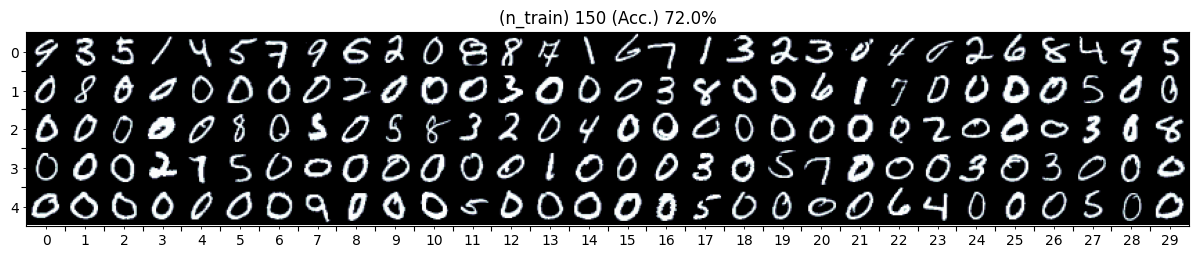

In [18]:
baseline = active_learn(
    S_train,
    S_pool,
    S_valid,
    random_acquisition,
    n_draws=21,
    n_budget=150,
    n_max_request=3,
    n_epochs=200,
)

Let's see the dynamics of the accuracy ...

In [19]:
def accuracy(scores):
    tp = scores.diagonal(axis1=-2, axis2=-1)
    return tp.sum(-1) / scores.sum((-2, -1))

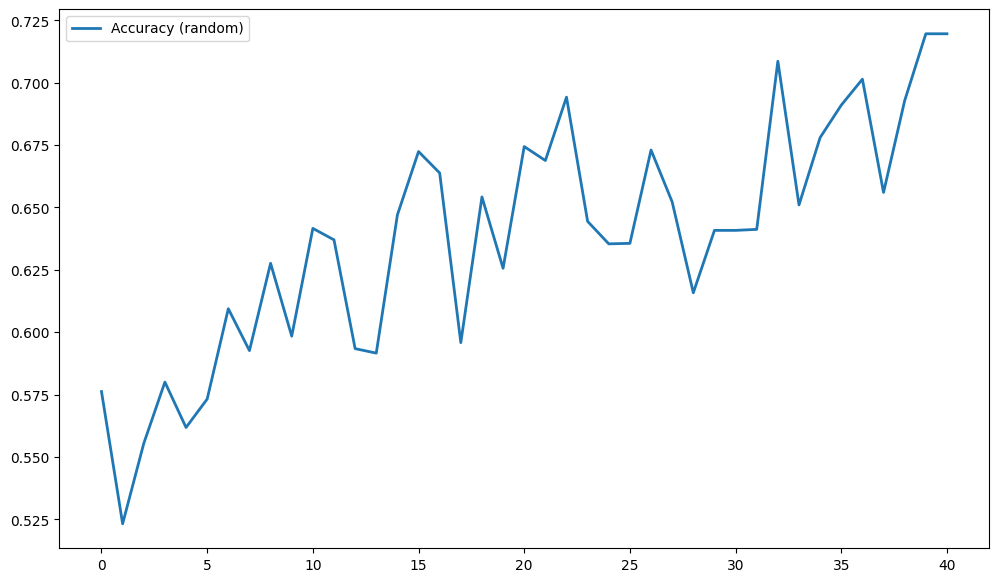

In [20]:
model_rand, train_rand, scores_rand, balances_rand = baseline

fig, ax = plt.subplots(1, 1, figsize=(12, 7))
ax.plot(accuracy(scores_rand), label='Accuracy (random)', lw=2)

ax.legend()
plt.show()

..., and the frequency of each class in $\mathcal{S}_\mathrm{train}$.

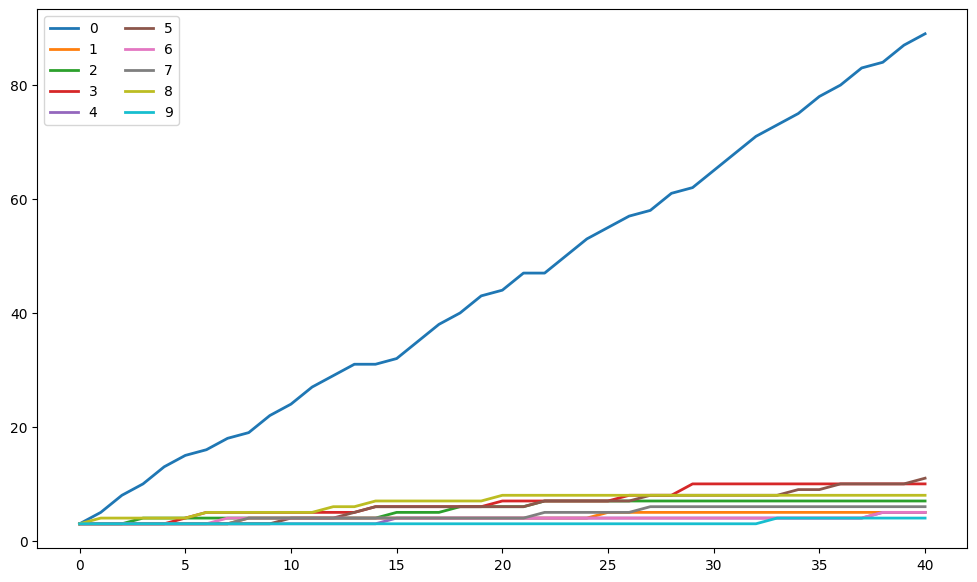

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(12, 7))

lines = ax.plot(balances_rand, lw=2)
plt.legend(lines, list(range(10)), ncol=2);

<br>

## Bayesian Active Learning by Disagreement

Bayesian Active Learning by Disagreement, or **BALD** criterion, is
based on the posterior mutual information between model's predictions
$y_x$ at some point $x$ and its parameters $\omega$:

$\begin{align}
    a(m, S)
        &= \sum_{x\in S} a(m, \{x\})
        \\
    a(m, \{x\})
        &= \mathbb{I}(y_x; \omega \mid x, m, D)
\end{align}
    \,, \tag{bald}
$

with the [**Mutual Information**](https://en.wikipedia.org/wiki/Mutual_information#Relation_to_Kullback%E2%80%93Leibler_divergence)
(**MI**)
$
    \mathbb{I}(y_x; \omega \mid x, m, D)
        = \mathbb{H}\bigl(
            \mathbb{E}_{\omega \sim q(\omega\mid m, D)}
                p(y_x \,\mid\, x, \omega, m, D)
        \bigr)
        - \mathbb{E}_{\omega \sim q(\omega\mid m, D)}
            \mathbb{H}\bigl(
                p(y_x \,\mid\, x, \omega, m, D)
            \bigr)
    \,, \tag{mi}
$

and the [(differential) **entropy**](https://en.wikipedia.org/wiki/Differential_entropy#Differential_entropies_for_various_distributions)
(all densities and/or probability mass functions can be conditional):

$
    \mathbb{H}(p(y))
        = - \mathbb{E}_{y\sim p} \log p(y)
    \,. $

<br>

#### (task) Implementing the acquisition function

Note that $a(m, S)$ is additively separable in $S$, i.e.
equals $\sum_{x\in S} a(m, \{x\})$. This implies

$
\begin{align}
    \max_{S \subseteq \mathcal{S}_\mathrm{unlabelled}} a(m, S)
        &= \max_{z \in \mathcal{S}_\mathrm{unlabelled}}
            \max_{F \in \mathcal{S}_\mathrm{unlabelled} \setminus \{z\}}
            \sum_{x\in F \cup \{x\}} a(m, \{x\})
        \\
        &= \max_{z \in \mathcal{S}_\mathrm{unlabelled}}
            a(m, \{z\})
            + \max_{F \in \mathcal{S}_\mathrm{unlabelled} \setminus \{z\}}
                \sum_{x\in F} a(m, \{x\})
\end{align}
    \,.
  $

Therefore selecting the $\ell$ `most interesting` points from
$\mathcal{S}_\mathrm{unlabelled}$ is trivial.

The acquisition function that we implement has interface
identical to `random_acquisition` but uses BALD to choose
instances.

In [22]:
def BALD_acquisition(dataset, model, n_request=1, n_draws=1):
    proba = sample_proba(model, dataset, n_draws=n_draws)
    mi = mutal_information(proba)
    return mi.argsort(descending=True)[:n_request]

    ## Exercise: implement BALD

    pass

<br>

#### (task) implementing entropy

For categorical (discrete) random variables $y \sim \mathcal{Cat}(\mathbf{p})$,
$\mathbf{p} \in \{ \mu \in [0, 1]^d \colon \sum_k \mu_k = 1\}$, the entropy is

$$
    \mathbb{H}(p(y))
        = - \mathbb{E}_{y\sim p(y)} \log p(y)
        = - \sum_k p_k \log p_k
    \,. $$

**(note)** although in calculus $0 \cdot \log 0 = 0$ (because
$\lim_{p\downarrow 0} p \cdot \log p = 0$), in floating point
arithmetic $0 \cdot \log 0 = \mathrm{NaN}$. So you need to add
some **really tiny float number** to the argument of $\log$.

In [23]:
def categorical_entropy(proba):
    """Compute the entropy along the last dimension."""

    ## Exercise: the probabilities sum to one along the last axis.
    #  Please, compute their entropy.
    return - torch.sum(proba * torch.log(proba + 1e-20), dim=-1)

<br>

#### (task) implementing mutual information

Consider a tensor $p_{bik}$ of probabilities $p(y_{x_i}=k \mid x_i, \omega_b, m, D)$
with $\omega_b \sim q(\omega \mid m, D)$ with $\mathcal{W} = (\omega_b)_{b=1}^B$
being iid draws from $q(\omega \mid m, D)$.

Let's implement a procedure that computes the Monte Carlo estimate of the
posterior predictive distribution, its **entropy** and **mutual information**

$
    \mathbb{I}_\mathrm{MC}(y_x; \omega \mid x, m, D)
        = \mathbb{H}\bigl(
            \hat{p}(y_x\mid x, m, D)
        \bigr)
        - \frac1{\lvert \mathcal{W} \rvert} \sum_{\omega\in \mathcal{W}}
            \mathbb{H}\bigl(
                p(y_x \,\mid\, x, \omega, m, D)
            \bigr)
    \,, \tag{mi-mc}
$
where
$
\hat{p}(y_x\mid x, m, D)
    = \frac1{\lvert \mathcal{W} \rvert} \sum_{\omega\in \mathcal{W}}
        \,p(y_x \mid x, \omega, m, D)
    \,.
$

In [25]:
def mutal_information(proba):
    ## Exercise: compute a Monte Carlo estimator of the predictive
    ##   distribution, its entropy and MI `H E_w p(., w) - E_w H p(., w)`
    entropy_exp = categorical_entropy(proba.mean(dim=0))
    exp_entropy = categorical_entropy(proba).mean(dim=0)
    return entropy_exp - exp_entropy

<br>

How powerful will our model with **BALD** acquisition, if we can afford no more than $150$ images?

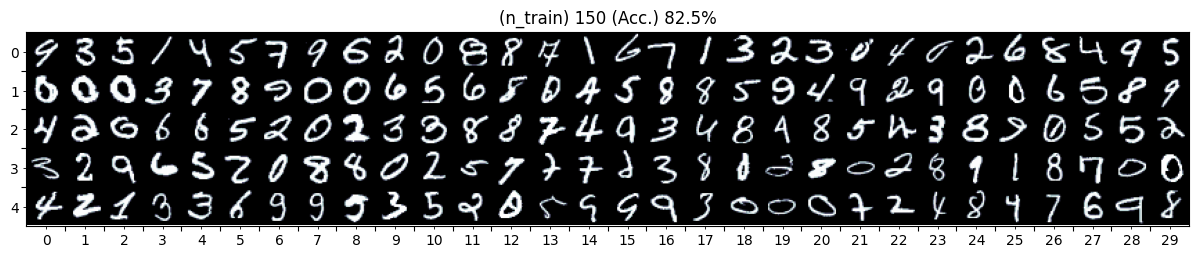

In [ ]:
bald_results = active_learn(
    S_train,
    S_pool,
    S_valid,
    BALD_acquisition,
    n_draws=21,
    n_budget=150,
    n_max_request=3,
    n_epochs=200,
)

Let's see the dynamics of the accuracy ...

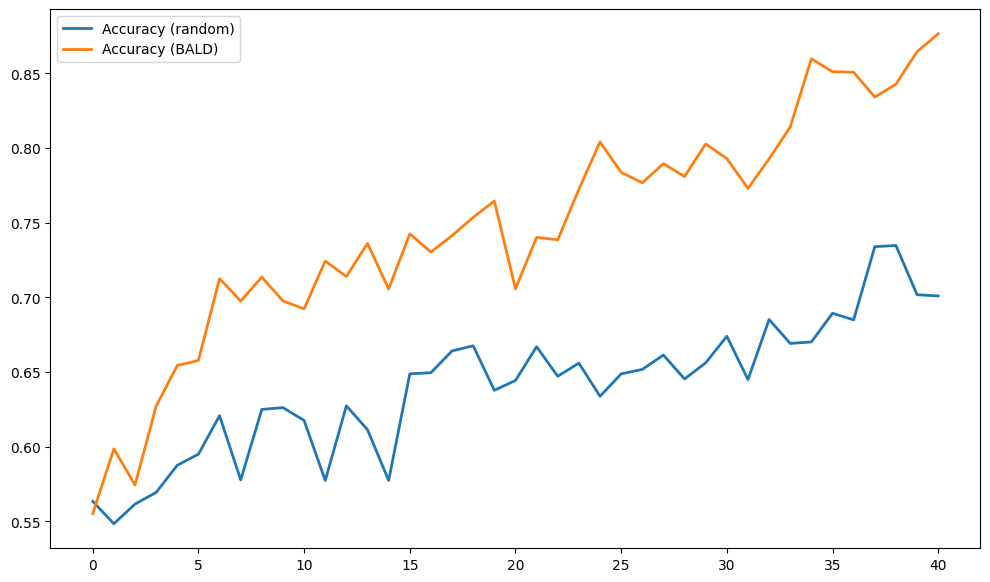

In [ ]:
model_bald, train_bald, scores_bald, balances_bald = bald_results

fig, ax = plt.subplots(1, 1, figsize=(12, 7))

ax.plot(accuracy(scores_rand), label='Accuracy (random)', lw=2)
ax.plot(accuracy(scores_bald), label='Accuracy (BALD)', lw=2)

ax.legend()
plt.show()

..., and the frequency of each class in $\mathcal{S}_\mathrm{train}$.

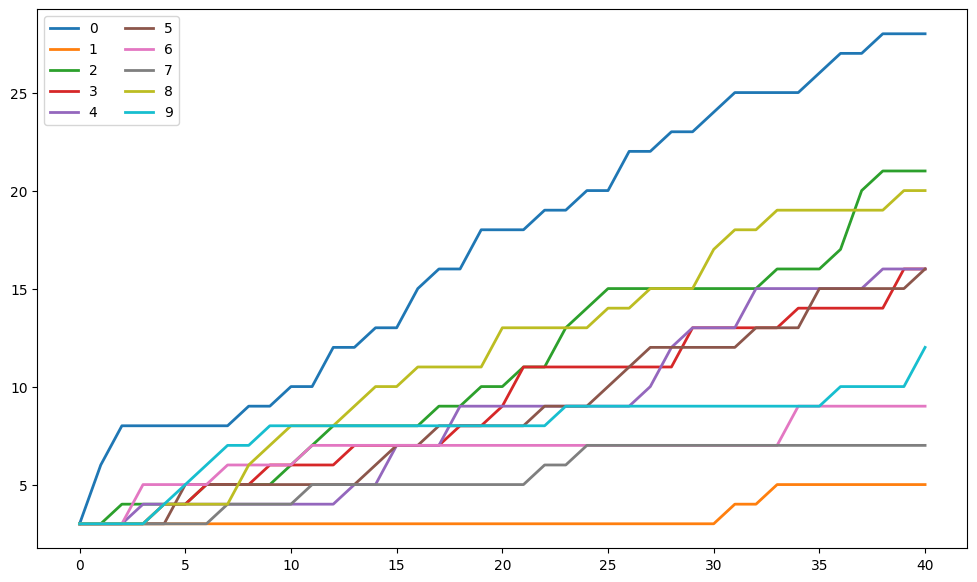

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(12, 7))

lines = ax.plot(balances_bald, lw=2)
plt.legend(lines, list(range(10)), ncol=2);

<br>

#### Class performance

The *one-versus-rest* precision / recall scores on
$\mathcal{S}_\mathrm{valid}$. For binary classification:

$$ \begin{align}
\mathrm{Precision}
    &= \frac{\mathrm{TP}}{\mathrm{TP} + \mathrm{FP}}
        \approx \mathbb{P}(y = 1 \mid \hat{y} = 1)
    \,, \\
\mathrm{Recall}
    &= \frac{\mathrm{TP}}{\mathrm{TP} + \mathrm{FN}}
        \approx \mathbb{P}(\hat{y} = 1 \mid y = 1)
    \,.
\end{align}$$

In [ ]:
import pandas as pd

def pr_scores(score_matrix):
    tp = score_matrix.diagonal(axis1=-2, axis2=-1)
    fp, fn = score_matrix.sum(axis=-2) - tp, score_matrix.sum(axis=-1) - tp

    return pd.DataFrame({
        "precision": {l: f"{p:.2%}" for l, p in enumerate(tp / (tp + fp))},
        "recall": {l: f"{p:.2%}" for l, p in enumerate(tp / (tp + fn))},
    })

Let's see the performance on the test set

In [ ]:
scores = {}
scores["rand"] = evaluate(model_rand, S_test, n_draws=21)
scores["bald"] = evaluate(model_bald, S_test, n_draws=21)

<br>

In [ ]:
df = pd.concat({
    name: pr_scores(score)
    for name, score in scores.items()
}, axis=1).T

df.swaplevel().sort_index()

0       1       2       3       4       5       6  \
precision bald  75.48%  97.39%  91.15%  90.79%  93.27%  88.85%  98.59%   
          rand  63.21%  78.77%  85.08%  78.32%  82.07%  71.22%  96.05%   
recall    bald  99.90%  85.46%  90.79%  83.96%  83.30%  89.35%  80.38%   
          rand  99.59%  95.77%  66.86%  84.75%  45.21%  74.89%  63.47%   

                     7       8       9  
precision bald  94.78%  76.28%  74.98%  
          rand  48.54%  68.78%  66.88%  
recall    bald  79.47%  86.86%  90.58%  
          rand  80.84%  50.21%  42.22%

<br>